# Movie Review Sentiment, Part 1: TextBlob vs. VADER

**Question:** how well do two popular prebuilt sentiment analyzers, TextBlob and VADER, tell positive movie reviews from negative ones, with no training at all?

**Data:** 25,000 labeled IMDB movie reviews (`labeledTrainData.tsv`), exactly half positive and half negative.

**Approach:** classify every review with each analyzer (a score of 0 or more counts as positive), then compare the predictions with the true labels using accuracy, precision, recall and confusion matrices.

**Key results:**
- TextBlob is 68.5% accurate and VADER is 69.4%, both better than the 50% expected from random guessing, but not by a wide margin.
- Both lean heavily positive. TextBlob calls 19,017 of the 25,000 reviews positive and labels 7,193 negative reviews as positive.
- TextBlob catches 94.6% of positive reviews but only 42.5% of negative ones. VADER is more balanced (85.8% and 53.0%).
- A model trained on the reviews themselves does much better (89.1% accuracy): see Part 2.

**Tools:** Python (pandas, TextBlob, vaderSentiment, scikit-learn, matplotlib)

**Context:** master's coursework (DSC550, Week 3), cleaned up and corrected for this portfolio. See the correction note at the end.

## 1. Load the data

In [1]:
# import libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

In [2]:
# load the labeled IMDB movie reviews (tab separated)
df_reviews = pd.read_csv('labeledTrainData.tsv', sep='\t', header=0)
df_reviews.shape

(25000, 3)

In [3]:
df_reviews.head()

,id,sentiment,review
0,5814_8,1,With all this stuff going down at the moment w...
1,2381_9,1,"\The Classic War of the Worlds\"" by Timothy Hi..."
2,7759_3,0,The film starts with a manager (Nicholas Bell)...
3,3630_4,0,It must be assumed that those who praised this...
4,9495_8,1,Superbly trashy and wondrously unpretentious 8...


## 2. How many positive and negative reviews are there?
The `sentiment` column is the true label from the dataset: 1 = positive, 0 = negative. It is kept unchanged throughout, so every prediction can be checked against it.

In [4]:
# true labels as words, so they can be compared directly with the analyzers' output
df_reviews['actual'] = df_reviews['sentiment'].map({1: 'positive', 0: 'negative'})
df_reviews['actual'].value_counts()

actual
positive    12500
negative    12500
Name: count, dtype: int64

## 3. TextBlob
TextBlob gives each review a polarity score from -1 (negative) to +1 (positive). Following the assignment rule, a score of 0 or more is classified as positive and below 0 as negative.

TextBlob and VADER are prebuilt analyzers, so nothing is trained here. That means there is no need for a train/test split: each analyzer is scored on all 25,000 reviews.

In [5]:
from textblob import TextBlob

# assign positive or negative sentiment based on TextBlob polarity (0 counts as positive)
def textblob_sentiment(review):
    polarity = TextBlob(review).sentiment.polarity
    return 'negative' if polarity < 0 else 'positive'

# predictions go in a new column so the true label is not overwritten
df_reviews['textblob_pred'] = df_reviews['review'].apply(textblob_sentiment)
df_reviews['textblob_pred'].value_counts()

textblob_pred
positive    19017
negative     5983
Name: count, dtype: int64

In [6]:
# accuracy against the true labels
tb_accuracy = accuracy_score(df_reviews['actual'], df_reviews['textblob_pred'])
print(f'TextBlob accuracy: {tb_accuracy:.1%}  (random guessing on a 50/50 dataset: 50.0%)')
print()
print(classification_report(df_reviews['actual'], df_reviews['textblob_pred'], digits=3))

TextBlob accuracy: 68.5%  (random guessing on a 50/50 dataset: 50.0%)



              precision    recall  f1-score   support

    negative      0.887     0.425     0.574     12500
    positive      0.622     0.946     0.750     12500

    accuracy                          0.685     25000
   macro avg      0.754     0.685     0.662     25000
weighted avg      0.754     0.685     0.662     25000



## 4. VADER
VADER (Valence Aware Dictionary and sEntiment Reasoner) was built for social media text. Its compound score also runs from -1 to +1, and the same rule is used: 0 or more = positive.

In [7]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()

# classify sentiment as positive or negative from VADER's compound score
def vader_sentiment(review):
    score = analyzer.polarity_scores(review)['compound']
    return 'positive' if score >= 0 else 'negative'

df_reviews['vader_pred'] = df_reviews['review'].apply(vader_sentiment)
df_reviews['vader_pred'].value_counts()

vader_pred
positive    16611
negative     8389
Name: count, dtype: int64

In [8]:
vader_accuracy = accuracy_score(df_reviews['actual'], df_reviews['vader_pred'])
print(f'VADER accuracy: {vader_accuracy:.1%}  (random guessing on a 50/50 dataset: 50.0%)')
print()
print(classification_report(df_reviews['actual'], df_reviews['vader_pred'], digits=3))

VADER accuracy: 69.4%  (random guessing on a 50/50 dataset: 50.0%)



              precision    recall  f1-score   support

    negative      0.789     0.530     0.634     12500
    positive      0.646     0.858     0.737     12500

    accuracy                          0.694     25000
   macro avg      0.718     0.694     0.686     25000
weighted avg      0.718     0.694     0.686     25000



## 5. Compare the two analyzers

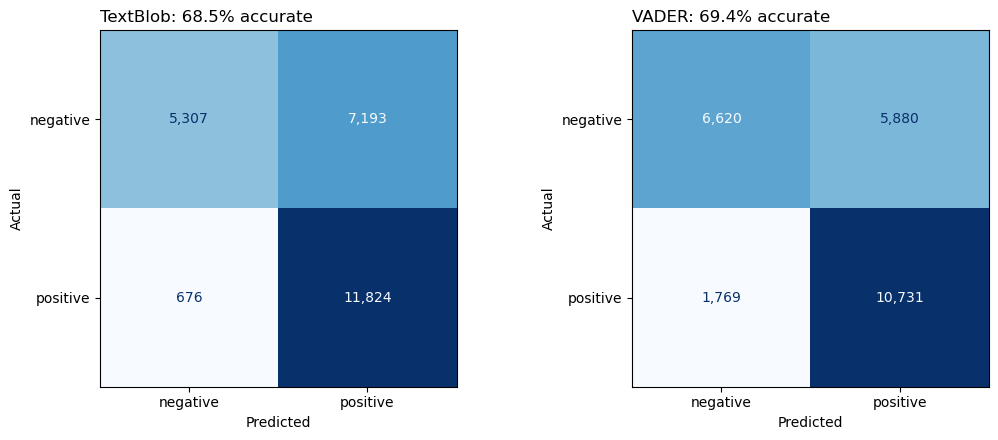

,accuracy,negative reviews called positive,positive reviews called negative
TextBlob,0.685,7193,676
VADER,0.694,5880,1769


In [9]:
# confusion matrices side by side
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, col, name in [(axes[0], 'textblob_pred', 'TextBlob'), (axes[1], 'vader_pred', 'VADER')]:
    cm = confusion_matrix(df_reviews['actual'], df_reviews[col], labels=['negative', 'positive'])
    ConfusionMatrixDisplay(cm, display_labels=['negative', 'positive']).plot(ax=ax, cmap='Blues', colorbar=False, values_format=',')
    acc = accuracy_score(df_reviews['actual'], df_reviews[col])
    ax.set_title(f'{name}: {acc:.1%} accurate', loc='left')
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

# where each analyzer goes wrong
summary = pd.DataFrame({
    'accuracy': [tb_accuracy, vader_accuracy],
    'negative reviews called positive': [((df_reviews['actual'] == 'negative') & (df_reviews[c] == 'positive')).sum() for c in ['textblob_pred', 'vader_pred']],
    'positive reviews called negative': [((df_reviews['actual'] == 'positive') & (df_reviews[c] == 'negative')).sum() for c in ['textblob_pred', 'vader_pred']],
}, index=['TextBlob', 'VADER'])
summary.round(3)

## Findings
- **Both analyzers beat random guessing, but only modestly:** 68.5% for TextBlob and 69.4% for VADER on a perfectly balanced set of 25,000 reviews.
- **Both lean positive.** TextBlob predicts 19,017 positive reviews when there are really 12,500, so 7,193 negative reviews are labeled positive. VADER predicts 16,611 positive and mislabels 5,880 negative reviews.
- **The trade-off is different.** TextBlob catches 94.6% of positive reviews but only 42.5% of negative ones. VADER catches fewer positives (85.8%) but more negatives (53.0%), which is why its overall accuracy is slightly higher.
- **Why they struggle:** both rely on general-purpose word lists. Movie reviews often describe dark plots in neutral language, use sarcasm, or praise one part of a film while panning the whole. Counting a score of exactly 0 as positive (the assignment rule) also adds a little positive bias.
- **Takeaway:** prebuilt analyzers are a fast starting point, but for a specific domain a model trained on labeled examples from that domain does far better. Part 2 trains one and reaches 89.1% accuracy on held-out reviews.

**Correction note:** the original coursework version replaced the true labels with each analyzer's predictions before checking accuracy, so it compared predictions with themselves. Its reported figures (65.7% and 75.2%) were 12,500 divided by the number of predicted positives, not accuracy. This version keeps the true labels and scores every review against them. The original notebook is in `earlier_versions/`.